PROFESSOR-FACING MODEL VALIDATION SUMMARY
          Target  CV_RMSE  CV_MAE  CV_R2
 Melt Pool Width   6.3732  5.0455 0.9554
 Melt Pool Depth  13.3576  9.7484 0.9743
Relative Density   0.0019  0.0010 0.8408
             UTS  28.6834 23.0977 0.7982


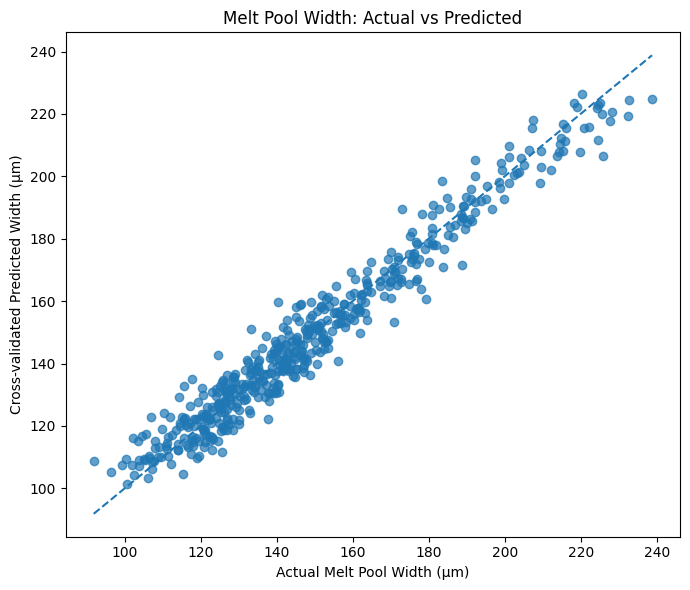

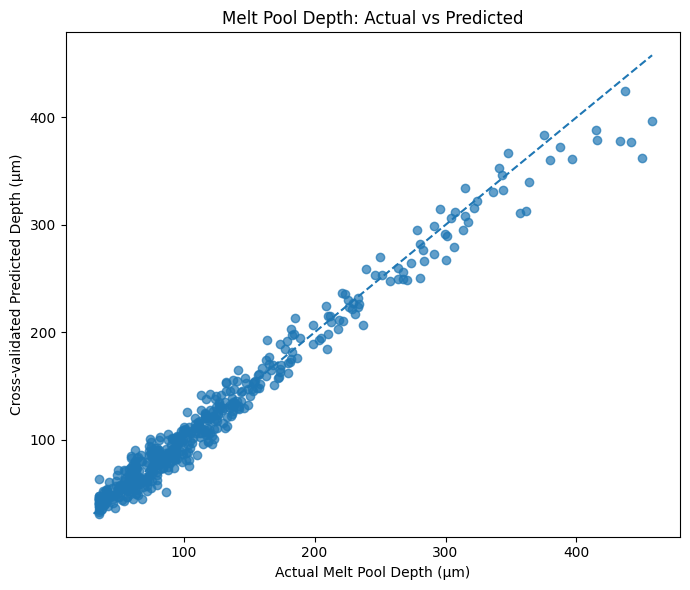

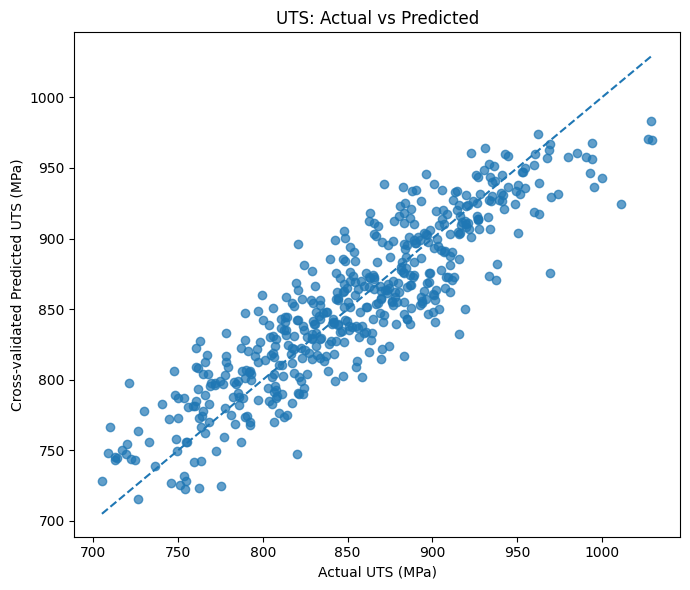

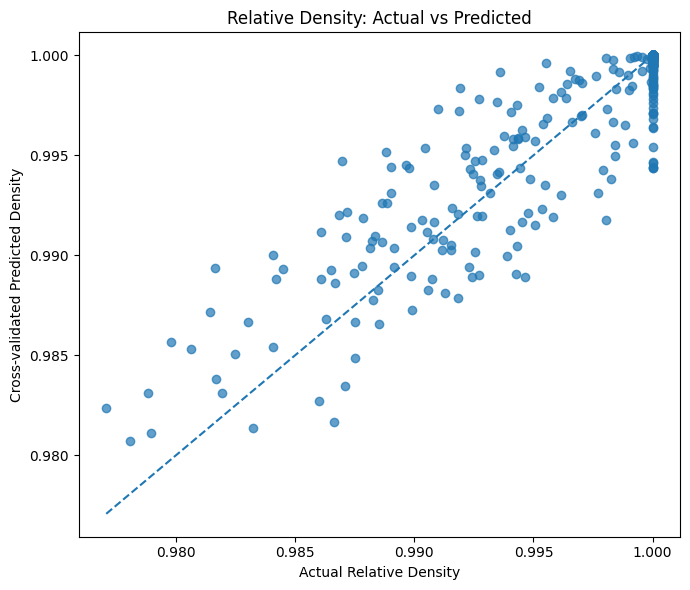

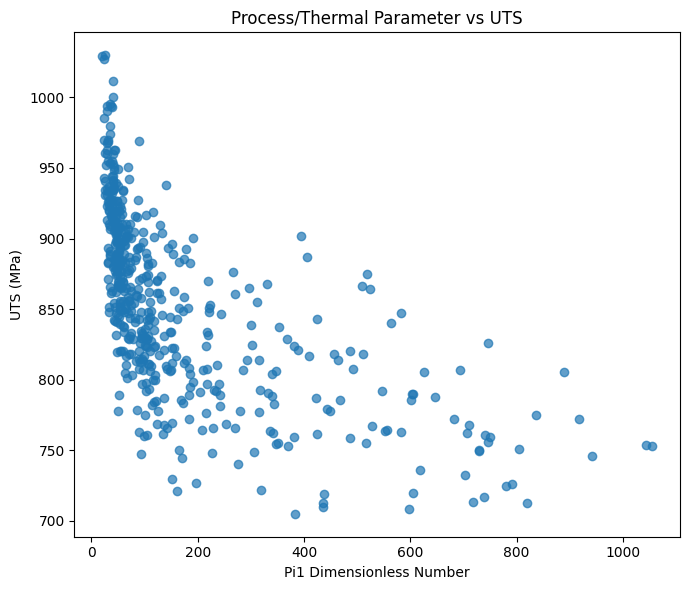

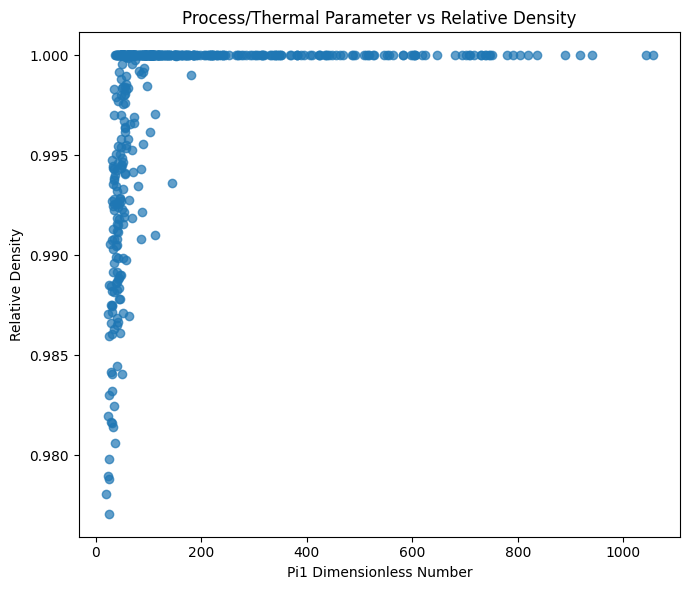

C:\Users\satya\AppData\Local\Temp\ipykernel_15852\1845442904.py:186: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["LOF (0)", "Optimal (1)", "Keyhole (2)"])


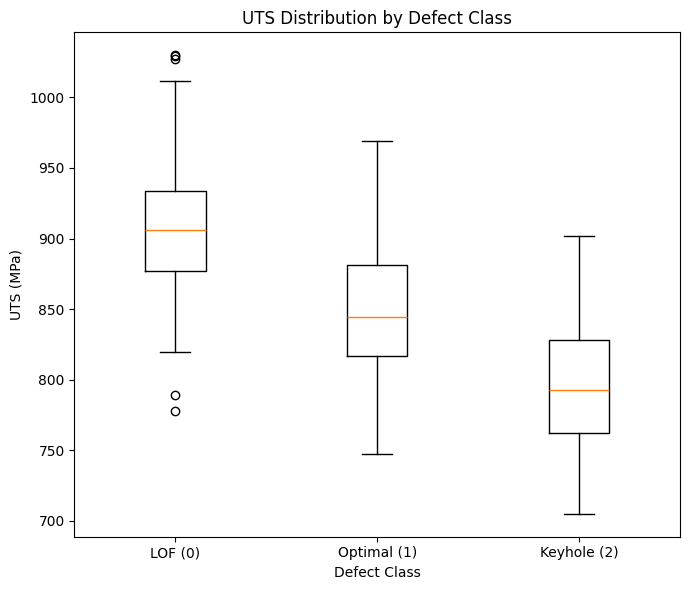


DEFECT CLASSIFICATION — 5-FOLD CROSS-VALIDATION
Accuracy      = 0.9580
Weighted F1   = 0.9580

Confusion Matrix:
[[181   5   0]
 [  7 149   4]
 [  0   5 149]]


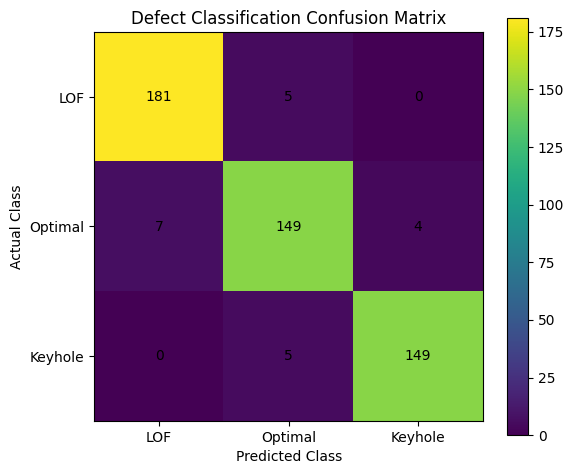

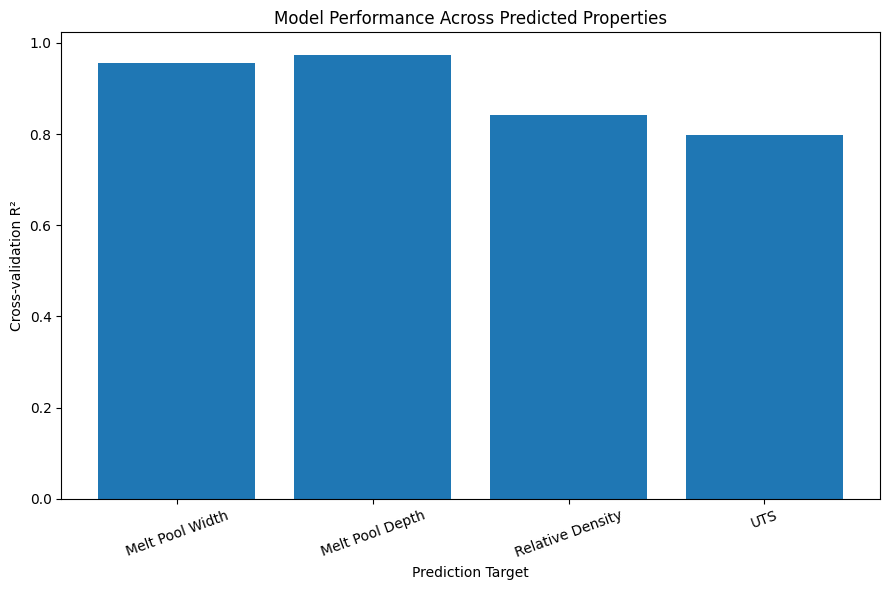


DATA QUALITY CHECK
Dataset size: 500 rows
Relative density minimum: 0.977081
Relative density maximum: 1.000000
Density values > 1: 0
Density values < 0: 0

UTS range:
Minimum: 704.98 MPa
Maximum: 1029.87 MPa
Mean:    853.53 MPa
Std:     63.91 MPa

Defect distribution:
DefectClass
0    186
1    160
2    154
Name: count, dtype: int64

GRAPH FILES SAVED
01_model_performance.png
02_defect_confusion_matrix.png
03_width_actual_vs_predicted.png
04_depth_actual_vs_predicted.png
05_uts_actual_vs_predicted.png
06_density_actual_vs_predicted.png
07_uts_vs_pi1.png
08_density_vs_pi1.png
09_uts_by_defect.png


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, accuracy_score, f1_score
from catboost import CatBoostRegressor, CatBoostClassifier

# ============================================================
# LOAD DATA
# ============================================================
df = pd.read_csv("haynes282_final_dataset.csv")

features = ["P_W", "v_mm_per_s", "h_mm", "t_mm"]
X = df[features]

# Fixed CV split for reproducible presentation results
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ============================================================
# HELPER
# ============================================================
def regression_results(name, y, model):
    pred = cross_val_predict(model, X, y, cv=cv)
    rmse = np.sqrt(mean_squared_error(y, pred))
    mae = mean_absolute_error(y, pred)
    r2 = r2_score(y, pred)
    return {
        "Target": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Actual": y.to_numpy(),
        "Predicted": pred
    }

# ============================================================
# 1. MODEL PERFORMANCE
# ============================================================
models = {
    "Melt Pool Width": CatBoostRegressor(
        iterations=300, depth=5, learning_rate=0.03,
        loss_function="RMSE", random_seed=42, verbose=False
    ),
    "Melt Pool Depth": CatBoostRegressor(
        iterations=300, depth=5, learning_rate=0.03,
        loss_function="RMSE", random_seed=42, verbose=False
    ),
    "Relative Density": RandomForestRegressor(
        n_estimators=300, max_depth=6, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "UTS": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])
}

targets = {
    "Melt Pool Width": df["MeltPoolWidth_um"],
    "Melt Pool Depth": df["MeltPoolDepth_um"],
    "Relative Density": df["RelativeDensity_frac"],
    "UTS": df["UTS_MPa"]
}

reg_results = {}
summary = []

for name, model in models.items():
    result = regression_results(name, targets[name], model)
    reg_results[name] = result
    summary.append({
        "Target": name,
        "CV_RMSE": result["RMSE"],
        "CV_MAE": result["MAE"],
        "CV_R2": result["R2"]
    })

summary_df = pd.DataFrame(summary)

print("=" * 70)
print("PROFESSOR-FACING MODEL VALIDATION SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ============================================================
# 2. ACTUAL VS PREDICTED — WIDTH
# ============================================================
plt.figure(figsize=(7, 6))
r = reg_results["Melt Pool Width"]
plt.scatter(r["Actual"], r["Predicted"], alpha=0.7)
mn = min(r["Actual"].min(), r["Predicted"].min())
mx = max(r["Actual"].max(), r["Predicted"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual Melt Pool Width (µm)")
plt.ylabel("Cross-validated Predicted Width (µm)")
plt.title("Melt Pool Width: Actual vs Predicted")
plt.tight_layout()
plt.savefig("03_width_actual_vs_predicted.png", dpi=300)
plt.show()

# ============================================================
# 3. ACTUAL VS PREDICTED — DEPTH
# ============================================================
plt.figure(figsize=(7, 6))
r = reg_results["Melt Pool Depth"]
plt.scatter(r["Actual"], r["Predicted"], alpha=0.7)
mn = min(r["Actual"].min(), r["Predicted"].min())
mx = max(r["Actual"].max(), r["Predicted"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual Melt Pool Depth (µm)")
plt.ylabel("Cross-validated Predicted Depth (µm)")
plt.title("Melt Pool Depth: Actual vs Predicted")
plt.tight_layout()
plt.savefig("04_depth_actual_vs_predicted.png", dpi=300)
plt.show()

# ============================================================
# 4. ACTUAL VS PREDICTED — UTS
# ============================================================
plt.figure(figsize=(7, 6))
r = reg_results["UTS"]
plt.scatter(r["Actual"], r["Predicted"], alpha=0.7)
mn = min(r["Actual"].min(), r["Predicted"].min())
mx = max(r["Actual"].max(), r["Predicted"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual UTS (MPa)")
plt.ylabel("Cross-validated Predicted UTS (MPa)")
plt.title("UTS: Actual vs Predicted")
plt.tight_layout()
plt.savefig("05_uts_actual_vs_predicted.png", dpi=300)
plt.show()

# ============================================================
# 5. ACTUAL VS PREDICTED — DENSITY
# ============================================================
plt.figure(figsize=(7, 6))
r = reg_results["Relative Density"]
plt.scatter(r["Actual"], r["Predicted"], alpha=0.7)
mn = min(r["Actual"].min(), r["Predicted"].min())
mx = max(r["Actual"].max(), r["Predicted"].max())
plt.plot([mn, mx], [mn, mx], linestyle="--")
plt.xlabel("Actual Relative Density")
plt.ylabel("Cross-validated Predicted Density")
plt.title("Relative Density: Actual vs Predicted")
plt.tight_layout()
plt.savefig("06_density_actual_vs_predicted.png", dpi=300)
plt.show()

# ============================================================
# 6. PI1 VS UTS
# ============================================================
plt.figure(figsize=(7, 6))
plt.scatter(df["Pi1_dimensionless"], df["UTS_MPa"], alpha=0.7)
plt.xlabel("Pi1 Dimensionless Number")
plt.ylabel("UTS (MPa)")
plt.title("Process/Thermal Parameter vs UTS")
plt.tight_layout()
plt.savefig("07_uts_vs_pi1.png", dpi=300)
plt.show()

# ============================================================
# 7. PI1 VS DENSITY
# ============================================================
plt.figure(figsize=(7, 6))
plt.scatter(df["Pi1_dimensionless"], df["RelativeDensity_frac"], alpha=0.7)
plt.xlabel("Pi1 Dimensionless Number")
plt.ylabel("Relative Density")
plt.title("Process/Thermal Parameter vs Relative Density")
plt.tight_layout()
plt.savefig("08_density_vs_pi1.png", dpi=300)
plt.show()

# ============================================================
# 8. UTS BY DEFECT CLASS
# ============================================================
groups = [
    df.loc[df["DefectClass"] == c, "UTS_MPa"].to_numpy()
    for c in [0, 1, 2]
]

plt.figure(figsize=(7, 6))
plt.boxplot(groups, labels=["LOF (0)", "Optimal (1)", "Keyhole (2)"])
plt.xlabel("Defect Class")
plt.ylabel("UTS (MPa)")
plt.title("UTS Distribution by Defect Class")
plt.tight_layout()
plt.savefig("09_uts_by_defect.png", dpi=300)
plt.show()

# ============================================================
# 9. DEFECT CLASSIFICATION — 5-FOLD CV
# ============================================================
clf = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function="MultiClass",
    random_seed=42,
    verbose=False
)

cls_pred = cross_val_predict(clf, X, df["DefectClass"], cv=cv)

acc = accuracy_score(df["DefectClass"], cls_pred)
f1 = f1_score(df["DefectClass"], cls_pred, average="weighted")
cm = confusion_matrix(df["DefectClass"], cls_pred, labels=[0, 1, 2])

print("\n" + "=" * 70)
print("DEFECT CLASSIFICATION — 5-FOLD CROSS-VALIDATION")
print("=" * 70)
print(f"Accuracy      = {acc:.4f}")
print(f"Weighted F1   = {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)

# ============================================================
# 10. CONFUSION MATRIX FIGURE
# ============================================================
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar()
plt.xticks([0, 1, 2], ["LOF", "Optimal", "Keyhole"])
plt.yticks([0, 1, 2], ["LOF", "Optimal", "Keyhole"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Defect Classification Confusion Matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.savefig("02_defect_confusion_matrix.png", dpi=300)
plt.show()

# ============================================================
# 11. MODEL PERFORMANCE BAR CHART
# ============================================================
plt.figure(figsize=(9, 6))
plt.bar(summary_df["Target"], summary_df["CV_R2"])
plt.ylabel("Cross-validation R²")
plt.xlabel("Prediction Target")
plt.title("Model Performance Across Predicted Properties")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("01_model_performance.png", dpi=300)
plt.show()

# ============================================================
# 12. DATA QUALITY CHECK
# ============================================================
print("\n" + "=" * 70)
print("DATA QUALITY CHECK")
print("=" * 70)

print(f"Dataset size: {len(df)} rows")
print(f"Relative density minimum: {df['RelativeDensity_frac'].min():.6f}")
print(f"Relative density maximum: {df['RelativeDensity_frac'].max():.6f}")
print(f"Density values > 1: {(df['RelativeDensity_frac'] > 1).sum()}")
print(f"Density values < 0: {(df['RelativeDensity_frac'] < 0).sum()}")

print("\nUTS range:")
print(f"Minimum: {df['UTS_MPa'].min():.2f} MPa")
print(f"Maximum: {df['UTS_MPa'].max():.2f} MPa")
print(f"Mean:    {df['UTS_MPa'].mean():.2f} MPa")
print(f"Std:     {df['UTS_MPa'].std():.2f} MPa")

print("\nDefect distribution:")
print(df["DefectClass"].value_counts().sort_index())

print("\n" + "=" * 70)
print("GRAPH FILES SAVED")
print("=" * 70)
for f in [
    "01_model_performance.png",
    "02_defect_confusion_matrix.png",
    "03_width_actual_vs_predicted.png",
    "04_depth_actual_vs_predicted.png",
    "05_uts_actual_vs_predicted.png",
    "06_density_actual_vs_predicted.png",
    "07_uts_vs_pi1.png",
    "08_density_vs_pi1.png",
    "09_uts_by_defect.png"
]:
    print(f)
